# Gesture-Controlled Photo Booth: Hyperparameter Tuning, `epochs`
**IAT 360 Computer Vision Project, Group 6.** Tuned by **Joseph Lee**.

Each group member changes one hyperparameter of the baseline (`Gesture_YOLO_Baseline.ipynb`) to three other values and compares against it. This hyperparameter is **`epochs`**, the maximum number of passes over the 1,280 training images.

| Run | epochs | Everything else |
|---|---|---|
| epochs_20 | 20 | same as baseline |
| epochs_35 | 35 | same as baseline |
| **Baseline** | **50** | YOLOv8s (COCO), SGD lr0 0.01, patience 15, batch 16, imgsz 640, seed 0, deterministic |
| epochs_80 | 80 | same as baseline |

**Hypothesis.** The baseline's best checkpoint was epoch 41 of 50, and validation is already almost perfect (mAP50 0.990). Fewer epochs (20, 35) test whether we can train faster for little loss (underfitting risk). More epochs (80) test whether longer training still helps on our own photos or starts to overfit to HaGRID.

**What `epochs` changes besides the length.** Ultralytics ties two schedules to the total: the learning rate decays linearly from `lr0` to `lr0 × lrf` over *all* epochs, and mosaic augmentation is switched off for the last 10 epochs (`close_mosaic=10`). So a 20-epoch run is not just the first 20 epochs of the baseline: its learning rate drops faster and half of it runs without mosaic. Early stopping (`patience=15`) stays the same as the baseline, so the 80-epoch run can stop before 80.

**Where this notebook comes from.** Joseph ran these experiments in Colab, as cells appended to `Gesture_YOLO_Baseline.ipynb` on his branch. They are moved here so the baseline notebook stays unchanged, and adapted to run locally like the other tuning notebooks:
- the Colab paths (`/content/...`) and the Google Drive backup cells are replaced by the repo's `models/` and `results/` folders
- the 20-epoch training cell is added (the Colab notebook only verified an existing 20-epoch checkpoint)
- each run's training history (`results.csv`, `results.png`, `args.yaml`) is saved next to its scores, for the training curves
- `evaluate()` runs at batch 16 like every other model (Joseph used batch 8 to fit the Colab T4)

All runs were trained on the same RTX 5060 Ti as the baseline, so the only difference is `epochs`. Joseph's original Colab numbers are kept in section 6 as an independent check.

In [1]:
import json, shutil
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

from gesture_eval import BASELINE, CLASSES, evaluate, error_analysis, summary_row, train_info

ROOT = Path.cwd()          # run this notebook from the repo root
assert (ROOT / "data.yaml").exists(), "Open the notebook from the repo root"
pd.set_option("display.precision", 3)
print("torch", torch.__version__, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Prepared dataset:", (ROOT / "dataset" / "images" / "train").exists())
for e in [20, 35, 80]:
    print(f"{e}-epoch checkpoint:", (ROOT / "models" / f"epochs_{e}_best.pt").exists())

torch 2.11.0+cu128 | NVIDIA GeForce RTX 5060 Ti
Prepared dataset: True
20-epoch checkpoint: True
35-epoch checkpoint: False
80-epoch checkpoint: False


## 1. Training
Joseph's training cell, written once as a function for the three runs: start from the COCO-pretrained `yolov8s.pt`, use the baseline settings with only `epochs` changed, and copy the best checkpoint to `models/epochs_<N>_best.pt`. A checkpoint that already exists is not retrained, so the notebook can be re-run for evaluation only.

In [2]:
def train_epochs(EPOCHS):
    RUN_NAME = f"epochs_{EPOCHS}"
    checkpoint = ROOT / "models" / f"{RUN_NAME}_best.pt"
    out = ROOT / "results" / RUN_NAME

    assert torch.cuda.is_available(), "GPU is not available."
    assert (ROOT / "dataset" / "images" / "train").exists(), "Dataset missing."

    if checkpoint.exists():
        print(f"{EPOCHS}-epoch checkpoint already exists. Skipping training.")
        return checkpoint

    model = YOLO("yolov8s.pt")
    settings = {**BASELINE, "epochs": EPOCHS}
    model.train(**settings, project=str(ROOT / "runs"), name=RUN_NAME, exist_ok=True, device=0)

    run_dir = Path(model.trainer.save_dir)
    checkpoint.parent.mkdir(exist_ok=True)
    shutil.copy2(run_dir / "weights" / "best.pt", checkpoint)

    # keep the training history next to the scores
    out.mkdir(parents=True, exist_ok=True)
    for f in ["results.csv", "results.png", "args.yaml"]:
        shutil.copy2(run_dir / f, out / f)
    info = train_info(run_dir / "results.csv")
    (out / "metrics.json").write_text(json.dumps(
        {"model": "yolov8s.pt (COCO-pretrained) fine-tuned", "changed": {"epochs": EPOCHS},
         "hyperparameters": settings, **info}, indent=2))
    print(f"{EPOCHS}-epoch model saved:", checkpoint.relative_to(ROOT), info)
    del model; torch.cuda.empty_cache()
    return checkpoint

## 2. 20 epochs

In [3]:
# Train 20-epoch model
checkpoint_20 = train_epochs(20)

20-epoch checkpoint already exists. Skipping training.


In [4]:
# Verify training for 20 epochs
model_20 = YOLO(str(checkpoint_20))

print("Model classes:", model_20.names)
print("Configured epochs:", model_20.ckpt["train_args"]["epochs"])
print("Training image size:", model_20.ckpt["train_args"]["imgsz"])

Model classes: {0: 'palm', 1: 'fist', 2: 'like', 3: 'dislike'}
Configured epochs: 20
Training image size: 640


In [5]:
# Evaluate 20-epoch against 50-epoch baseline:
# fist detection, hand-size performance and individual detection failures
out = ROOT / "results" / "epochs_20"

overall_20, per_class_20 = evaluate(weights=checkpoint_20, imgsz=640, out_dir=out)
analysis_20 = error_analysis(weights=checkpoint_20, imgsz=640, out_dir=out)

display(overall_20.round(4))
print("20-epoch error summary:")
print({k: analysis_20["summary"][k] for k in ["hands", "predictions", "correct", "precision", "recall", "F1", "accuracy"]})
print("\nPerformance by gesture:")
display(analysis_20["by_class"])
print("\nPerformance by hand size:")
display(analysis_20["by_size"])

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2731.0±312.8 MB/s, size: 1460.9 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 47.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.5it/s 2.8s.2ss
                   all        160        160      0.985      0.968      0.993      0.742
Speed: 0.7ms preprocess, 3.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\epochs_20_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 par

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.985,0.969,0.977,0.993,0.742
"test, all (160)",0.857,0.848,0.853,0.870,0.464
"test, team only (128)",0.823,0.819,0.821,0.844,0.415


20-epoch error summary:
{'hands': 154, 'predictions': 167, 'correct': 129, 'precision': 0.7725, 'recall': 0.8377, 'F1': 0.8037, 'accuracy': 0.6719}

Performance by gesture:


,hands,recall,precision,missed,wrong_class
palm,33.0,0.818,0.871,3.0,3.0
fist,36.0,0.694,0.625,11.0,0.0
like,42.0,0.905,0.792,3.0,1.0
dislike,43.0,0.907,0.812,2.0,2.0



Performance by hand size:


,hands,recall,missed
size,,,
small (<1%),16,0.625,5
medium (1-5%),86,0.872,9
large (>5%),52,0.846,5


## 3. 35 epochs

In [6]:
# Train 35-epoch model
checkpoint_35 = train_epochs(35)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937,

In [7]:
# Evaluate training
out = ROOT / "results" / "epochs_35"

overall_35, per_class_35 = evaluate(weights=checkpoint_35, imgsz=640, out_dir=out)
analysis_35 = error_analysis(weights=checkpoint_35, imgsz=640, out_dir=out)

display(overall_35.round(4))
display(analysis_35["by_class"])

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2696.5±358.9 MB/s, size: 1295.5 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 83.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.7it/s 2.7s.2ss
                   all        160        160      0.988      0.984      0.994       0.74
Speed: 0.5ms preprocess, 2.9ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\epochs_35_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 par

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.988,0.984,0.986,0.994,0.740
"test, all (160)",0.892,0.778,0.831,0.886,0.493
"test, team only (128)",0.870,0.729,0.793,0.846,0.432


,hands,recall,precision,missed,wrong_class
palm,33.0,0.758,0.806,5.0,3.0
fist,36.0,0.583,0.583,13.0,2.0
like,42.0,0.786,0.868,8.0,1.0
dislike,43.0,0.907,0.812,2.0,2.0


## 4. 80 epochs

In [8]:
# Train 80-epoch model
checkpoint_80 = train_epochs(80)

New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937,

In [9]:
# Evaluate 80 epochs
out = ROOT / "results" / "epochs_80"

overall_80, per_class_80 = evaluate(weights=checkpoint_80, imgsz=640, out_dir=out)
analysis_80 = error_analysis(weights=checkpoint_80, imgsz=640, out_dir=out)

display(overall_80.round(4))
display(analysis_80["by_class"])

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2398.4±424.0 MB/s, size: 1295.5 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 74.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.8it/s 3.6s.1s
                   all        160        160      0.991      0.974      0.987      0.742
Speed: 0.7ms preprocess, 3.6ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\epochs_80_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 para

,precision,recall,F1,mAP50,mAP50-95
validation (160),0.991,0.974,0.982,0.987,0.742
"test, all (160)",0.869,0.868,0.869,0.879,0.474
"test, team only (128)",0.853,0.827,0.840,0.843,0.414


,hands,recall,precision,missed,wrong_class
palm,33.0,0.848,0.875,5.0,0.0
fist,36.0,0.639,0.657,12.0,1.0
like,42.0,0.857,0.900,5.0,1.0
dislike,43.0,0.930,0.952,2.0,1.0


## 5. Comparison with the baseline (50 epochs)
All four models scored with the same `gesture_eval.py` on the same data. The baseline row is read from `results/baseline/` (written by the baseline notebook). The **team-only test set (128 of our own photos)** is the headline.

In [10]:
RUNS = {50: "baseline", **{v: f"epochs_{v}" for v in [20, 35, 80]}}
summary = pd.DataFrame({name: {"epochs": v, **summary_row(ROOT / "results" / name)}
                        for v, name in sorted(RUNS.items())}).T.rename_axis("run")
summary.round(4).to_csv(ROOT / "results" / "tuning_epochs_summary.csv")
summary

,epochs,epochs_run,best_epoch,train_minutes,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,P @ conf 0.25,R @ conf 0.25,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,,,,,,,,,,,
epochs_20,20.0,20.0,18.0,4.2,0.993,0.742,0.823,0.819,0.821,0.844,0.415,0.636,0.625,0.772,0.838,0.804,0.672
epochs_35,35.0,35.0,30.0,5.9,0.994,0.740,0.870,0.729,0.793,0.846,0.432,0.630,0.500,0.771,0.766,0.769,0.624
baseline,50.0,50.0,41.0,15.3,0.990,0.748,0.894,0.775,0.830,0.845,0.418,0.625,0.562,0.838,0.805,0.821,0.697
epochs_80,80.0,67.0,52.0,12.9,0.987,0.742,0.853,0.827,0.840,0.843,0.414,0.628,0.562,0.852,0.825,0.838,0.722


### Change from the baseline (team-only test)
Positive = better than the baseline (epochs 50). Single-model differences under about ±0.06 team mAP50 are within the noise of our 128 photos (bootstrap, see the baseline report).

In [11]:
metric_cols = ["val mAP50", "val mAP50-95", "team P", "team R", "team F1", "team mAP50", "team mAP50-95",
               "team fist mAP50", "small-hand recall", "F1 @ conf 0.25", "accuracy @ conf 0.25"]
summary[metric_cols] = summary[metric_cols].astype(float)
(summary[metric_cols] - summary.loc["baseline", metric_cols]).drop("baseline").round(3)

,val mAP50,val mAP50-95,team P,team R,team F1,team mAP50,team mAP50-95,team fist mAP50,small-hand recall,F1 @ conf 0.25,accuracy @ conf 0.25
run,,,,,,,,,,,
epochs_20,0.003,-0.006,-0.070,0.044,-0.009,-0.001,-0.003,0.011,0.063,-0.018,-0.025
epochs_35,0.004,-0.008,-0.024,-0.046,-0.037,0.001,0.013,0.005,-0.062,-0.052,-0.072
epochs_80,-0.003,-0.005,-0.041,0.052,0.010,-0.002,-0.004,0.003,0.000,0.017,0.025


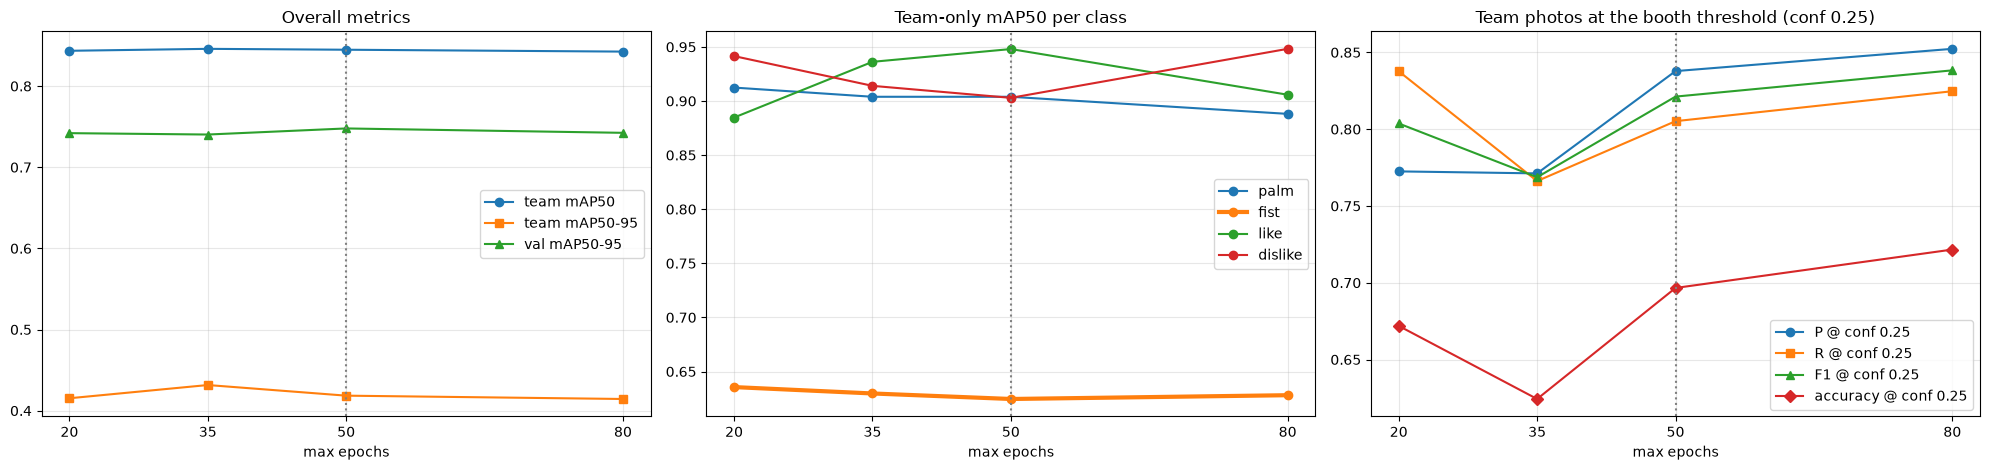

In [12]:
xs = sorted(RUNS)
names = [RUNS[x] for x in xs]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

ax = axes[0]
for col, mk in [("team mAP50", "o"), ("team mAP50-95", "s"), ("val mAP50-95", "^")]:
    ax.plot(xs, summary.loc[names, col], marker=mk, label=col)
ax.set_title("Overall metrics"); ax.legend()

ax = axes[1]
pc = pd.DataFrame({x: pd.read_csv(ROOT / "results" / RUNS[x] / "per_class.csv", index_col=[0, 1])
                   .loc["test (team only)", "mAP50"] for x in xs}).loc[CLASSES]
for c in CLASSES:
    ax.plot(xs, pc.loc[c, xs], marker="o", lw=3 if c == "fist" else 1.5, label=c)
ax.set_title("Team-only mAP50 per class"); ax.legend()

ax = axes[2]
for col, mk in [("P @ conf 0.25", "o"), ("R @ conf 0.25", "s"), ("F1 @ conf 0.25", "^"), ("accuracy @ conf 0.25", "D")]:
    ax.plot(xs, summary.loc[names, col], marker=mk, label=col)
ax.set_title("Team photos at the booth threshold (conf 0.25)"); ax.legend()

for ax in axes:
    ax.set_xlabel("max epochs"); ax.set_xticks(xs); ax.grid(alpha=0.3); ax.axvline(50, color="grey", ls=":")
plt.tight_layout()
fig.savefig(ROOT / "results" / "tuning_epochs_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

### The hands the baseline missed
For every team-photo hand the baseline got wrong at conf 0.25: what each `epochs` model predicted for it (`team_hands.csv`).

In [13]:
key = ["file", "gt_index"]
team_hands = {x: pd.read_csv(ROOT / "results" / RUNS[x] / "team_hands.csv") for x in xs}
base = team_hands[[x for x in xs if RUNS[x] == "baseline"][0]]
wrong = base.loc[~base["correct"], key + ["person", "class", "area_frac"]].copy()
wrong["area %"] = (wrong.pop("area_frac") * 100).round(2)
for x in xs:
    if RUNS[x] != "baseline":
        wrong[RUNS[x]] = wrong.merge(team_hands[x], on=key, how="left")["pred_class"].values
fixed = {RUNS[x]: int((wrong[RUNS[x]] == wrong["class"]).sum()) for x in xs if RUNS[x] != "baseline"}
broke = {RUNS[x]: int((base["correct"].values & ~team_hands[x]["correct"].values).sum()) for x in xs if RUNS[x] != "baseline"}
print(f"baseline errors: {len(wrong)} | fixed: {fixed} | newly wrong: {broke}")
wrong.sort_values("area %").reset_index(drop=True)

baseline errors: 30 | fixed: {'epochs_20': 11, 'epochs_35': 6, 'epochs_80': 12} | newly wrong: {'epochs_20': 6, 'epochs_35': 12, 'epochs_80': 9}


,file,gt_index,person,class,area %,epochs_20,epochs_35,epochs_80
0,dislike_385.jpg,0,Daff,dislike,0.16,missed,missed,missed
1,fist_370.jpg,3,Amy,fist,0.26,missed,missed,missed
2,fist_370.jpg,2,Amy,fist,0.29,missed,missed,missed
3,fist_398.jpg,0,Joseph,fist,0.54,missed,fist,fist
4,like_372.jpg,1,Amy,like,0.68,like,missed,like
5,like_372.jpg,0,Amy,like,0.72,fist,fist,fist
6,fist_390.jpg,0,Daff,fist,0.89,missed,missed,missed
7,like_373.jpg,1,Amy,like,1.22,missed,missed,missed
8,fist_376.jpg,1,Amy,fist,1.38,fist,fist,fist
9,dislike_375.jpg,1,Amy,dislike,1.59,dislike,dislike,dislike


### Correct and incorrect examples
`error_analysis()` saves both grids for every run (`results/epochs_<value>/correct_cases.jpg` and `failure_cases.jpg`). Green boxes are the labels, red boxes are predictions at conf 0.25. Shown here for the best run by team mAP50.

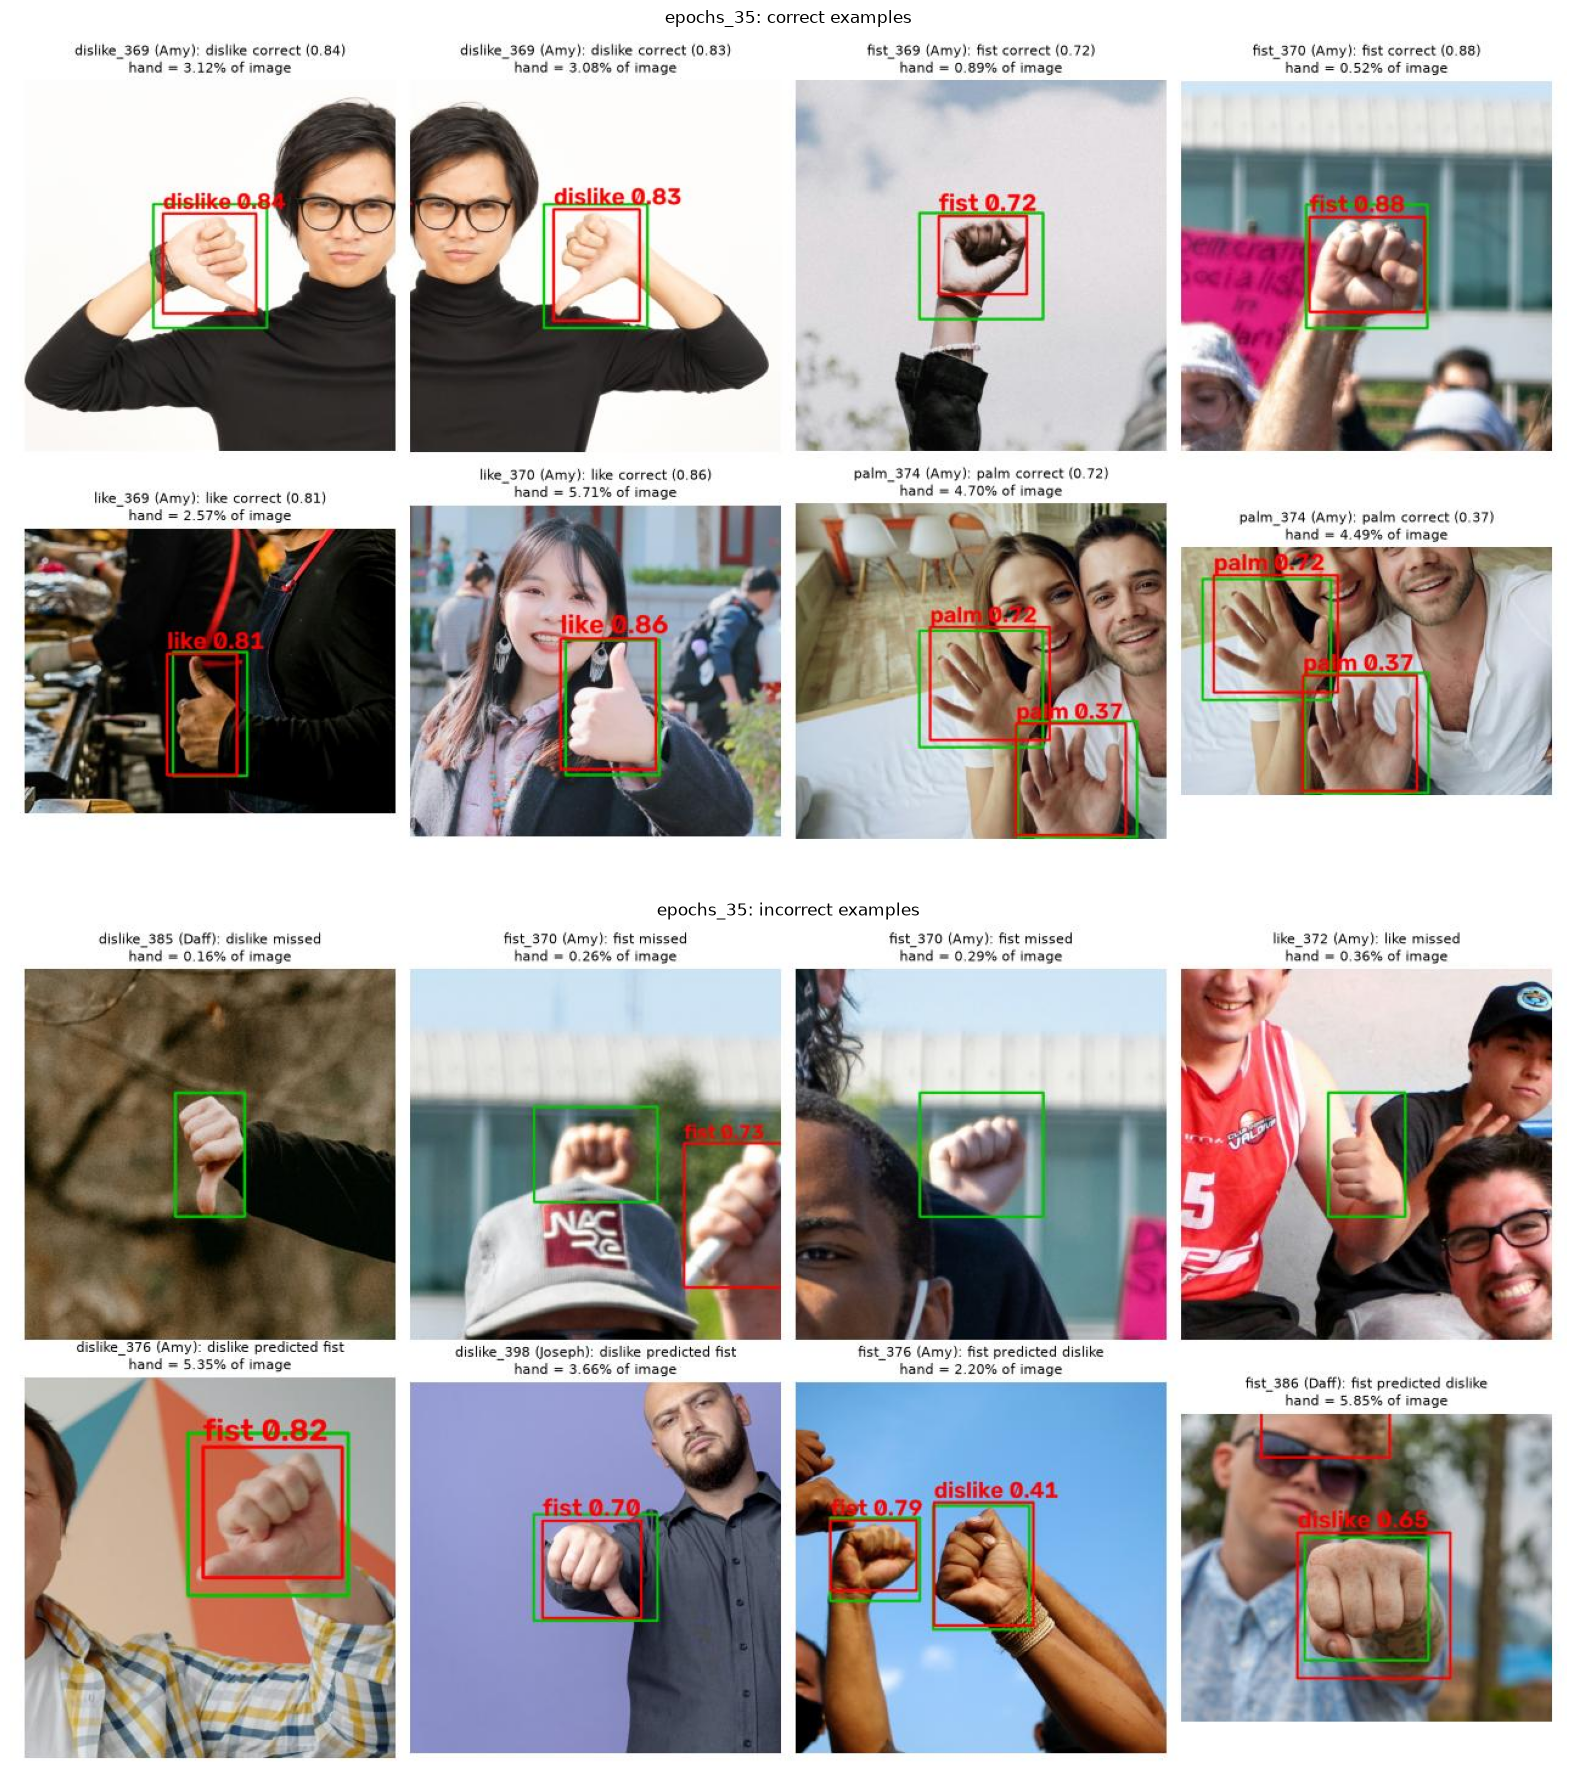

In [14]:
best_run = summary.drop("baseline")["team mAP50"].astype(float).idxmax()
fig, axes = plt.subplots(2, 1, figsize=(16, 18))
for ax, f, title in zip(axes, ["correct_cases.jpg", "failure_cases.jpg"], ["correct", "incorrect"]):
    ax.imshow(plt.imread(ROOT / "results" / best_run / f)); ax.set_title(f"{best_run}: {title} examples"); ax.axis("off")
plt.tight_layout(); plt.show()

### 5.1 Training curves: underfitting or overfitting?
Validation mAP50-95 and validation losses per epoch for every run (from each run's `results.csv`). Dots mark the best checkpoint, which is the one we keep.

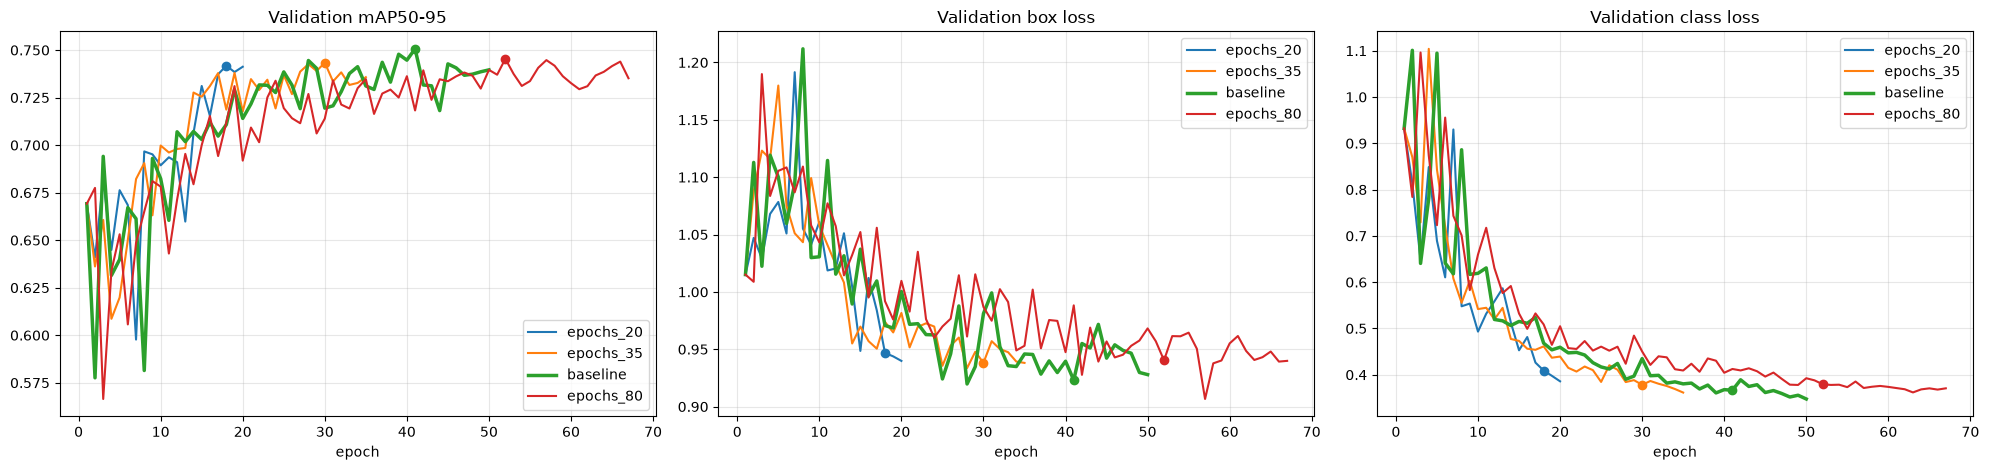

,epochs_run,best_epoch,train_minutes
run,,,
epochs_20,20.0,18.0,4.2
epochs_35,35.0,30.0,5.9
baseline,50.0,41.0,15.3
epochs_80,67.0,52.0,12.9


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for x in xs:
    h = pd.read_csv(ROOT / "results" / RUNS[x] / "results.csv")
    h.columns = h.columns.str.strip()
    b = h["metrics/mAP50-95(B)"].idxmax()
    for ax, col in zip(axes, ["metrics/mAP50-95(B)", "val/box_loss", "val/cls_loss"]):
        line, = ax.plot(h["epoch"], h[col], label=RUNS[x], lw=2.5 if RUNS[x] == "baseline" else 1.5)
        ax.plot(h.loc[b, "epoch"], h.loc[b, col], "o", color=line.get_color())
for ax, t in zip(axes, ["Validation mAP50-95", "Validation box loss", "Validation class loss"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
fig.savefig(ROOT / "results" / "tuning_epochs_curves.png", dpi=110, bbox_inches="tight")
plt.show()
summary[["epochs_run", "best_epoch", "train_minutes"]]

## 6. Cross-check: Joseph's Colab runs
Joseph's original runs (Colab, Tesla T4, printed in the notebook on his branch). They are a separate training run on different hardware, and his copy of the labels had one extra box in `dislike_393` (155 hands instead of 154), so small differences from the tables above are expected.

| Run | Team P | Team R | Team F1 | Team mAP50 | Team mAP50-95 | Epochs run |
|---|---|---|---|---|---|---|
| epochs_20 | 0.878 | 0.796 | 0.835 | 0.840 | 0.426 | 20 |
| epochs_35 | 0.881 | 0.838 | 0.859 | 0.859 | 0.437 | 35 |
| epochs_80 | 0.853 | 0.777 | 0.813 | 0.857 | 0.406 | 60 (early stop) |

## 7. Discussion
_Filled in after the runs._